# Minigaláxia N-body em 2D

## Do potencial de Plummer a um disco autogravitante

Este notebook transforma o primeiro bloco da palestra do professor Rubens Machado — **gravitação** — em um experimento computacional executável no Google Colab.

Vamos construir duas versões com as **mesmas 500 partículas iniciais**:

1. **partículas-teste em um halo fixo:** as partículas sentem o potencial do halo, mas não interagem entre si;
2. **halo fixo + disco autogravitante:** além do halo, cada partícula sente todas as demais partículas do disco.

O objetivo não é produzir uma galáxia espiral fotorrealista. Queremos verificar se conseguimos criar um disco estelar numericamente ligado, rotacionalmente sustentado e com conservação aceitável de energia e momento angular.

> **Como usar no Colab:** faça upload deste `.ipynb`, escolha **Ambiente de execução → Executar tudo** e aguarde a simulação autogravitante. CPU é suficiente; GPU não é necessária.


## 1. Modelo físico e unidades

Cada partícula representa um **pacote de massa estelar** — uma superpartícula — e não uma única estrela. Trabalhamos em duas dimensões com

\[
\mathbf q_i=(m_i,x_i,y_i,v_{x,i},v_{y,i}).
\]

O halo de matéria escura é fixo e usa o potencial de Plummer:

\[
\Phi_h(r)=-\frac{GM_h}{\sqrt{r^2+a_h^2}},
\qquad
\mathbf a_h=-\frac{GM_h\mathbf r}{(r^2+a_h^2)^{3/2}}.
\]

Quando ativamos a autogravidade, a aceleração total é

\[
\mathbf a_i=\mathbf a_h(\mathbf r_i)
+G\sum_{j\ne i}m_j
\frac{\mathbf r_j-\mathbf r_i}
{\left(|\mathbf r_j-\mathbf r_i|^2+\epsilon^2\right)^{3/2}}.
\]

O softening \(\epsilon\) evita forças artificialmente enormes durante encontros muito próximos entre superpartículas. A integração temporal usa **Leapfrog kick–drift–kick**.

Unidades internas:

- distância: kpc;
- massa: \(M_\odot\);
- tempo: Myr;
- velocidade: kpc/Myr, convertida para km/s apenas nos gráficos.


In [1]:
import time
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

try:
    from numba import njit
    NUMBA_AVAILABLE = True
except ImportError:
    NUMBA_AVAILABLE = False

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.20,
    "font.size": 11,
})

# G em kpc^3 / (Msun Myr^2)
G = 4.498502151575286e-12
KPC_MYR_TO_KM_S = 977.79222168

print("Numba disponível:", NUMBA_AVAILABLE)
print("A semente fixa torna as condições iniciais reprodutíveis.")


Numba disponível: False
A semente fixa torna as condições iniciais reprodutíveis.


In [2]:
@dataclass(frozen=True)
class GalaxyParams:
    n: int = 500
    m_halo: float = 2.0e11       # Msun
    a_halo: float = 6.0          # kpc
    m_disk: float = 4.0e10       # Msun
    r_disk: float = 3.0          # kpc: escala exponencial
    r_max: float = 15.0          # kpc: truncamento inicial
    epsilon: float = 0.50        # kpc: softening
    dt: float = 0.50             # Myr
    t_end: float = 500.0         # Myr
    record_every: int = 5        # salva um quadro a cada 2.5 Myr
    seed: int = 20261027


p = GalaxyParams()
p


GalaxyParams(n=500, m_halo=200000000000.0, a_halo=6.0, m_disk=40000000000.0, r_disk=3.0, r_max=15.0, epsilon=0.5, dt=0.5, t_end=500.0, record_every=5, seed=20261027)

## 2. Forças gravitacionais

A soma direta custa \(O(N^2)\). Para \(N=500\), isso ainda é adequado para um Colab gratuito. Quando o Numba está disponível, o laço de pares é compilado; caso contrário, o notebook usa uma versão vetorizada em NumPy.


In [3]:
def halo_acceleration(pos, p):
    r2 = np.sum(pos * pos, axis=1)
    return -G * p.m_halo * pos / (r2 + p.a_halo**2)[:, None] ** 1.5


def disk_acceleration_numpy(pos, particle_mass, epsilon):
    # delta[i, j] = r_j - r_i
    delta = pos[None, :, :] - pos[:, None, :]
    dist2 = np.sum(delta * delta, axis=2) + epsilon**2
    inv_r3 = dist2 ** -1.5
    np.fill_diagonal(inv_r3, 0.0)
    return G * particle_mass * np.sum(delta * inv_r3[:, :, None], axis=1)


if NUMBA_AVAILABLE:
    @njit
    def disk_acceleration_numba(pos, particle_mass, epsilon):
        n = pos.shape[0]
        acc = np.zeros_like(pos)
        eps2 = epsilon * epsilon
        for i in range(n):
            ax = 0.0
            ay = 0.0
            for j in range(n):
                if i != j:
                    dx = pos[j, 0] - pos[i, 0]
                    dy = pos[j, 1] - pos[i, 1]
                    d2 = dx * dx + dy * dy + eps2
                    inv_r3 = 1.0 / (d2 * np.sqrt(d2))
                    ax += G * particle_mass * dx * inv_r3
                    ay += G * particle_mass * dy * inv_r3
            acc[i, 0] = ax
            acc[i, 1] = ay
        return acc


def disk_acceleration(pos, particle_mass, epsilon):
    if NUMBA_AVAILABLE:
        return disk_acceleration_numba(pos, particle_mass, epsilon)
    return disk_acceleration_numpy(pos, particle_mass, epsilon)


def total_acceleration(pos, p, self_gravity):
    acc = halo_acceleration(pos, p)
    if self_gravity:
        acc += disk_acceleration(pos, p.m_disk / p.n, p.epsilon)
    return acc


## 3. Condições iniciais

Os raios seguem aproximadamente um disco exponencial, cuja distribuição radial é

\[
p(r)\propto r\,e^{-r/R_d}.
\]

Para o caso autogravitante, a velocidade circular inclui uma aproximação da massa do disco interior a \(r\):

\[
M_d(<r)=M_d\left[1-e^{-r/R_d}\left(1+\frac{r}{R_d}\right)\right].
\]

Tratamos essa massa como esférica apenas para inicializar as velocidades. Isso **não é uma função de distribuição de equilíbrio exata** para um disco fino; portanto, alguma reorganização radial será física/numericamente esperada.


In [4]:
def sample_exponential_disk(p):
    rng = np.random.default_rng(p.seed)
    radii = []
    while len(radii) < p.n:
        draw = rng.gamma(shape=2.0, scale=p.r_disk, size=2 * p.n)
        accepted = draw[(draw >= 0.35) & (draw <= p.r_max)]
        radii.extend(accepted.tolist())

    r = np.asarray(radii[:p.n])
    theta = rng.uniform(0.0, 2.0 * np.pi, p.n)
    pos = np.column_stack((r * np.cos(theta), r * np.sin(theta)))
    return pos, rng


def circular_speed_halo(r, p):
    vc2 = G * p.m_halo * r**2 / (r**2 + p.a_halo**2) ** 1.5
    return np.sqrt(np.maximum(vc2, 0.0))


def enclosed_exponential_disk_mass(r, p):
    x = r / p.r_disk
    return p.m_disk * (1.0 - np.exp(-x) * (1.0 + x))


def make_initial_conditions(p, include_disk_support, dispersion_fraction=0.025):
    pos, rng = sample_exponential_disk(p)
    r = np.linalg.norm(pos, axis=1)
    er = pos / r[:, None]
    et = np.column_stack((-er[:, 1], er[:, 0]))

    vc2 = circular_speed_halo(r, p) ** 2
    if include_disk_support:
        vc2 += G * enclosed_exponential_disk_mass(r, p) / r
    vc = np.sqrt(np.maximum(vc2, 0.0))

    # Pequena dispersão: o disco não nasce perfeitamente "frio".
    sigma = dispersion_fraction * vc
    v_radial = rng.normal(0.0, sigma)
    v_tangent = vc + rng.normal(0.0, sigma)
    vel = v_radial[:, None] * er + v_tangent[:, None] * et
    vel -= np.mean(vel, axis=0, keepdims=True)
    return pos, vel


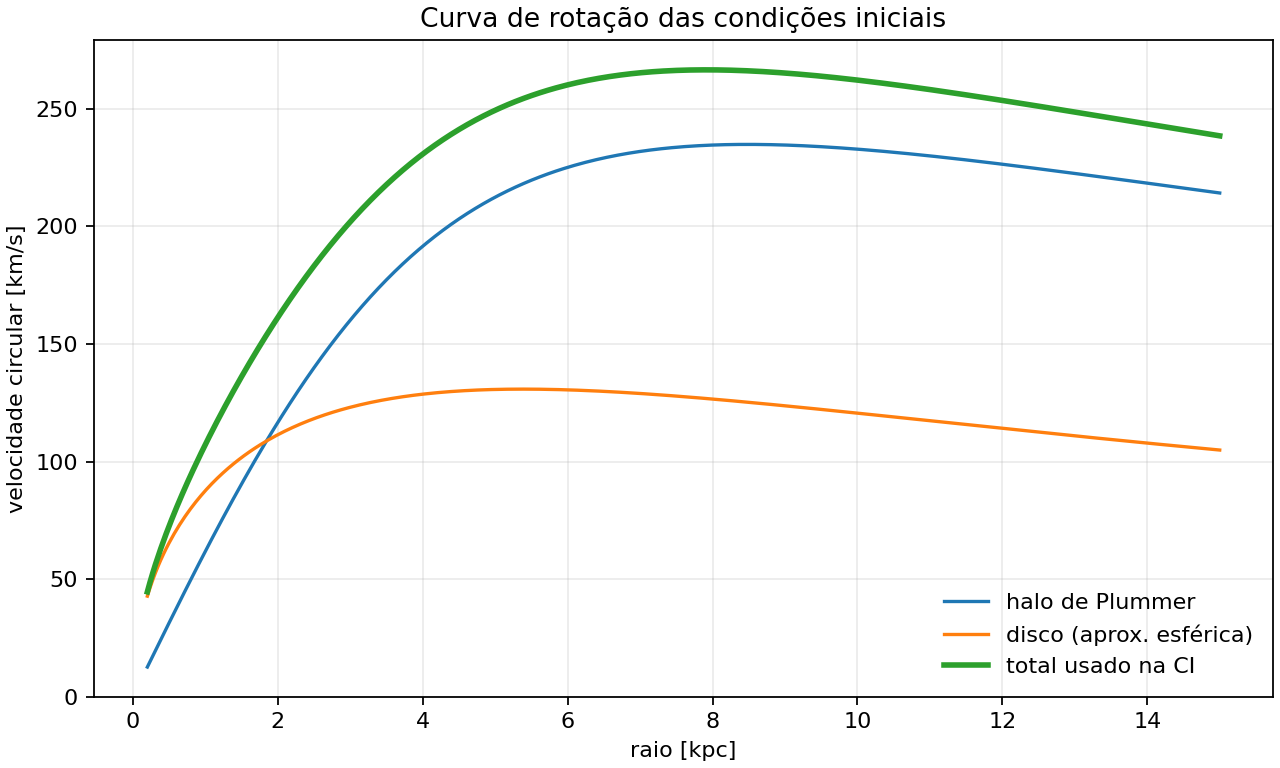

In [5]:
r_curve = np.linspace(0.2, p.r_max, 400)
v_halo = circular_speed_halo(r_curve, p) * KPC_MYR_TO_KM_S
v_disk = np.sqrt(G * enclosed_exponential_disk_mass(r_curve, p) / r_curve) * KPC_MYR_TO_KM_S
v_total = np.sqrt(v_halo**2 + v_disk**2)

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
ax.plot(r_curve, v_halo, label="halo de Plummer")
ax.plot(r_curve, v_disk, label="disco (aprox. esférica)")
ax.plot(r_curve, v_total, lw=2.5, label="total usado na CI")
ax.set(xlabel="raio [kpc]", ylabel="velocidade circular [km/s]",
       title="Curva de rotação das condições iniciais")
ax.legend(frameon=False)
fig.savefig("curva_rotacao_inicial.png", dpi=160)
plt.show()


## 4. Leapfrog e diagnósticos

O integrador executa

\[
\mathbf v_{n+1/2}=\mathbf v_n+\frac{\Delta t}{2}\mathbf a_n,
\quad
\mathbf r_{n+1}=\mathbf r_n+\Delta t\,\mathbf v_{n+1/2},
\quad
\mathbf v_{n+1}=\mathbf v_{n+1/2}+\frac{\Delta t}{2}\mathbf a_{n+1}.
\]

Monitoramos energia total, momento angular \(L_z\), quantis radiais e deslocamento do centro de massa.


In [6]:
def diagnostics(pos, vel, p, self_gravity):
    m = p.m_disk / p.n
    kinetic = 0.5 * m * np.sum(vel * vel)

    r2 = np.sum(pos * pos, axis=1)
    phi_halo = -G * p.m_halo / np.sqrt(r2 + p.a_halo**2)
    potential_halo = m * np.sum(phi_halo)

    potential_disk = 0.0
    if self_gravity:
        delta = pos[None, :, :] - pos[:, None, :]
        dist = np.sqrt(np.sum(delta * delta, axis=2) + p.epsilon**2)
        upper = np.triu_indices(p.n, k=1)
        potential_disk = -G * m * m * np.sum(1.0 / dist[upper])

    energy = kinetic + potential_halo + potential_disk
    lz = m * np.sum(pos[:, 0] * vel[:, 1] - pos[:, 1] * vel[:, 0])
    radius = np.sqrt(r2)
    com_offset = np.linalg.norm(np.mean(pos, axis=0))
    return energy, lz, np.quantile(radius, [0.1, 0.5, 0.9]), com_offset


def integrate(pos0, vel0, p, self_gravity):
    pos = pos0.copy()
    vel = vel0.copy()
    n_steps = int(round(p.t_end / p.dt))

    times, positions = [], []
    energies, angular_momenta, radii, com_offsets = [], [], [], []

    def record(step):
        energy, lz, rq, com = diagnostics(pos, vel, p, self_gravity)
        times.append(step * p.dt)
        positions.append(pos.copy())
        energies.append(energy)
        angular_momenta.append(lz)
        radii.append(rq)
        com_offsets.append(com)

    acc = total_acceleration(pos, p, self_gravity)
    record(0)
    start = time.perf_counter()

    for step in range(1, n_steps + 1):
        vel_half = vel + 0.5 * p.dt * acc
        pos = pos + p.dt * vel_half
        acc_new = total_acceleration(pos, p, self_gravity)
        vel = vel_half + 0.5 * p.dt * acc_new
        acc = acc_new

        if step % p.record_every == 0 or step == n_steps:
            record(step)

    return {
        "time": np.asarray(times),
        "positions": np.asarray(positions),
        "energy": np.asarray(energies),
        "lz": np.asarray(angular_momenta),
        "r_quantiles": np.asarray(radii),
        "com_offset": np.asarray(com_offsets),
        "runtime": time.perf_counter() - start,
    }


def summarize(name, result):
    de = (result["energy"][-1] - result["energy"][0]) / abs(result["energy"][0])
    dl = (result["lz"][-1] - result["lz"][0]) / abs(result["lz"][0])
    r0 = result["r_quantiles"][0]
    rf = result["r_quantiles"][-1]
    r_final = np.linalg.norm(result["positions"][-1], axis=1)

    print(name)
    print(f"  tempo de execução       = {result['runtime']:.2f} s")
    print(f"  deriva final de energia = {de:+.3e}")
    print(f"  deriva final de Lz      = {dl:+.3e}")
    print(f"  r10/r50/r90 inicial     = {r0.round(3)} kpc")
    print(f"  r10/r50/r90 final       = {rf.round(3)} kpc")
    print(f"  maior offset do CM      = {result['com_offset'].max():.3f} kpc")
    print(f"  fração final em r<20    = {np.mean(r_final < 20.0):.3f}")


## 5. Experimento A — halo fixo e partículas-teste


In [7]:
halo_pos, halo_vel = make_initial_conditions(p, include_disk_support=False)
halo_result = integrate(halo_pos, halo_vel, p, self_gravity=False)
summarize("HALO FIXO", halo_result)


HALO FIXO
  tempo de execução       = 0.04 s
  deriva final de energia = +2.817e-08
  deriva final de Lz      = +4.776e-16
  r10/r50/r90 inicial     = [ 1.732  5.04  10.035] kpc
  r10/r50/r90 final       = [ 1.737  5.002 10.144] kpc
  maior offset do CM      = 0.490 kpc
  fração final em r<20    = 1.000


O halo fixo funciona como nosso teste de controle: se as velocidades circulares e o Leapfrog estiverem corretos, o perfil radial deve permanecer quase constante.

## 6. Experimento B — halo + disco autogravitante

Esta é a parte \(O(N^2)\). No primeiro uso do Numba, a compilação acrescenta alguns segundos; as execuções seguintes ficam mais rápidas.


In [8]:
self_pos, self_vel = make_initial_conditions(p, include_disk_support=True)
self_result = integrate(self_pos, self_vel, p, self_gravity=True)
summarize("HALO + DISCO AUTOGRAVITANTE", self_result)


HALO + DISCO AUTOGRAVITANTE
  tempo de execução       = 18.81 s
  deriva final de energia = -6.071e-08
  deriva final de Lz      = +1.375e-16
  r10/r50/r90 inicial     = [ 1.732  5.04  10.035] kpc
  r10/r50/r90 final       = [ 1.657  4.838 11.711] kpc
  maior offset do CM      = 0.401 kpc
  fração final em r<20    = 1.000


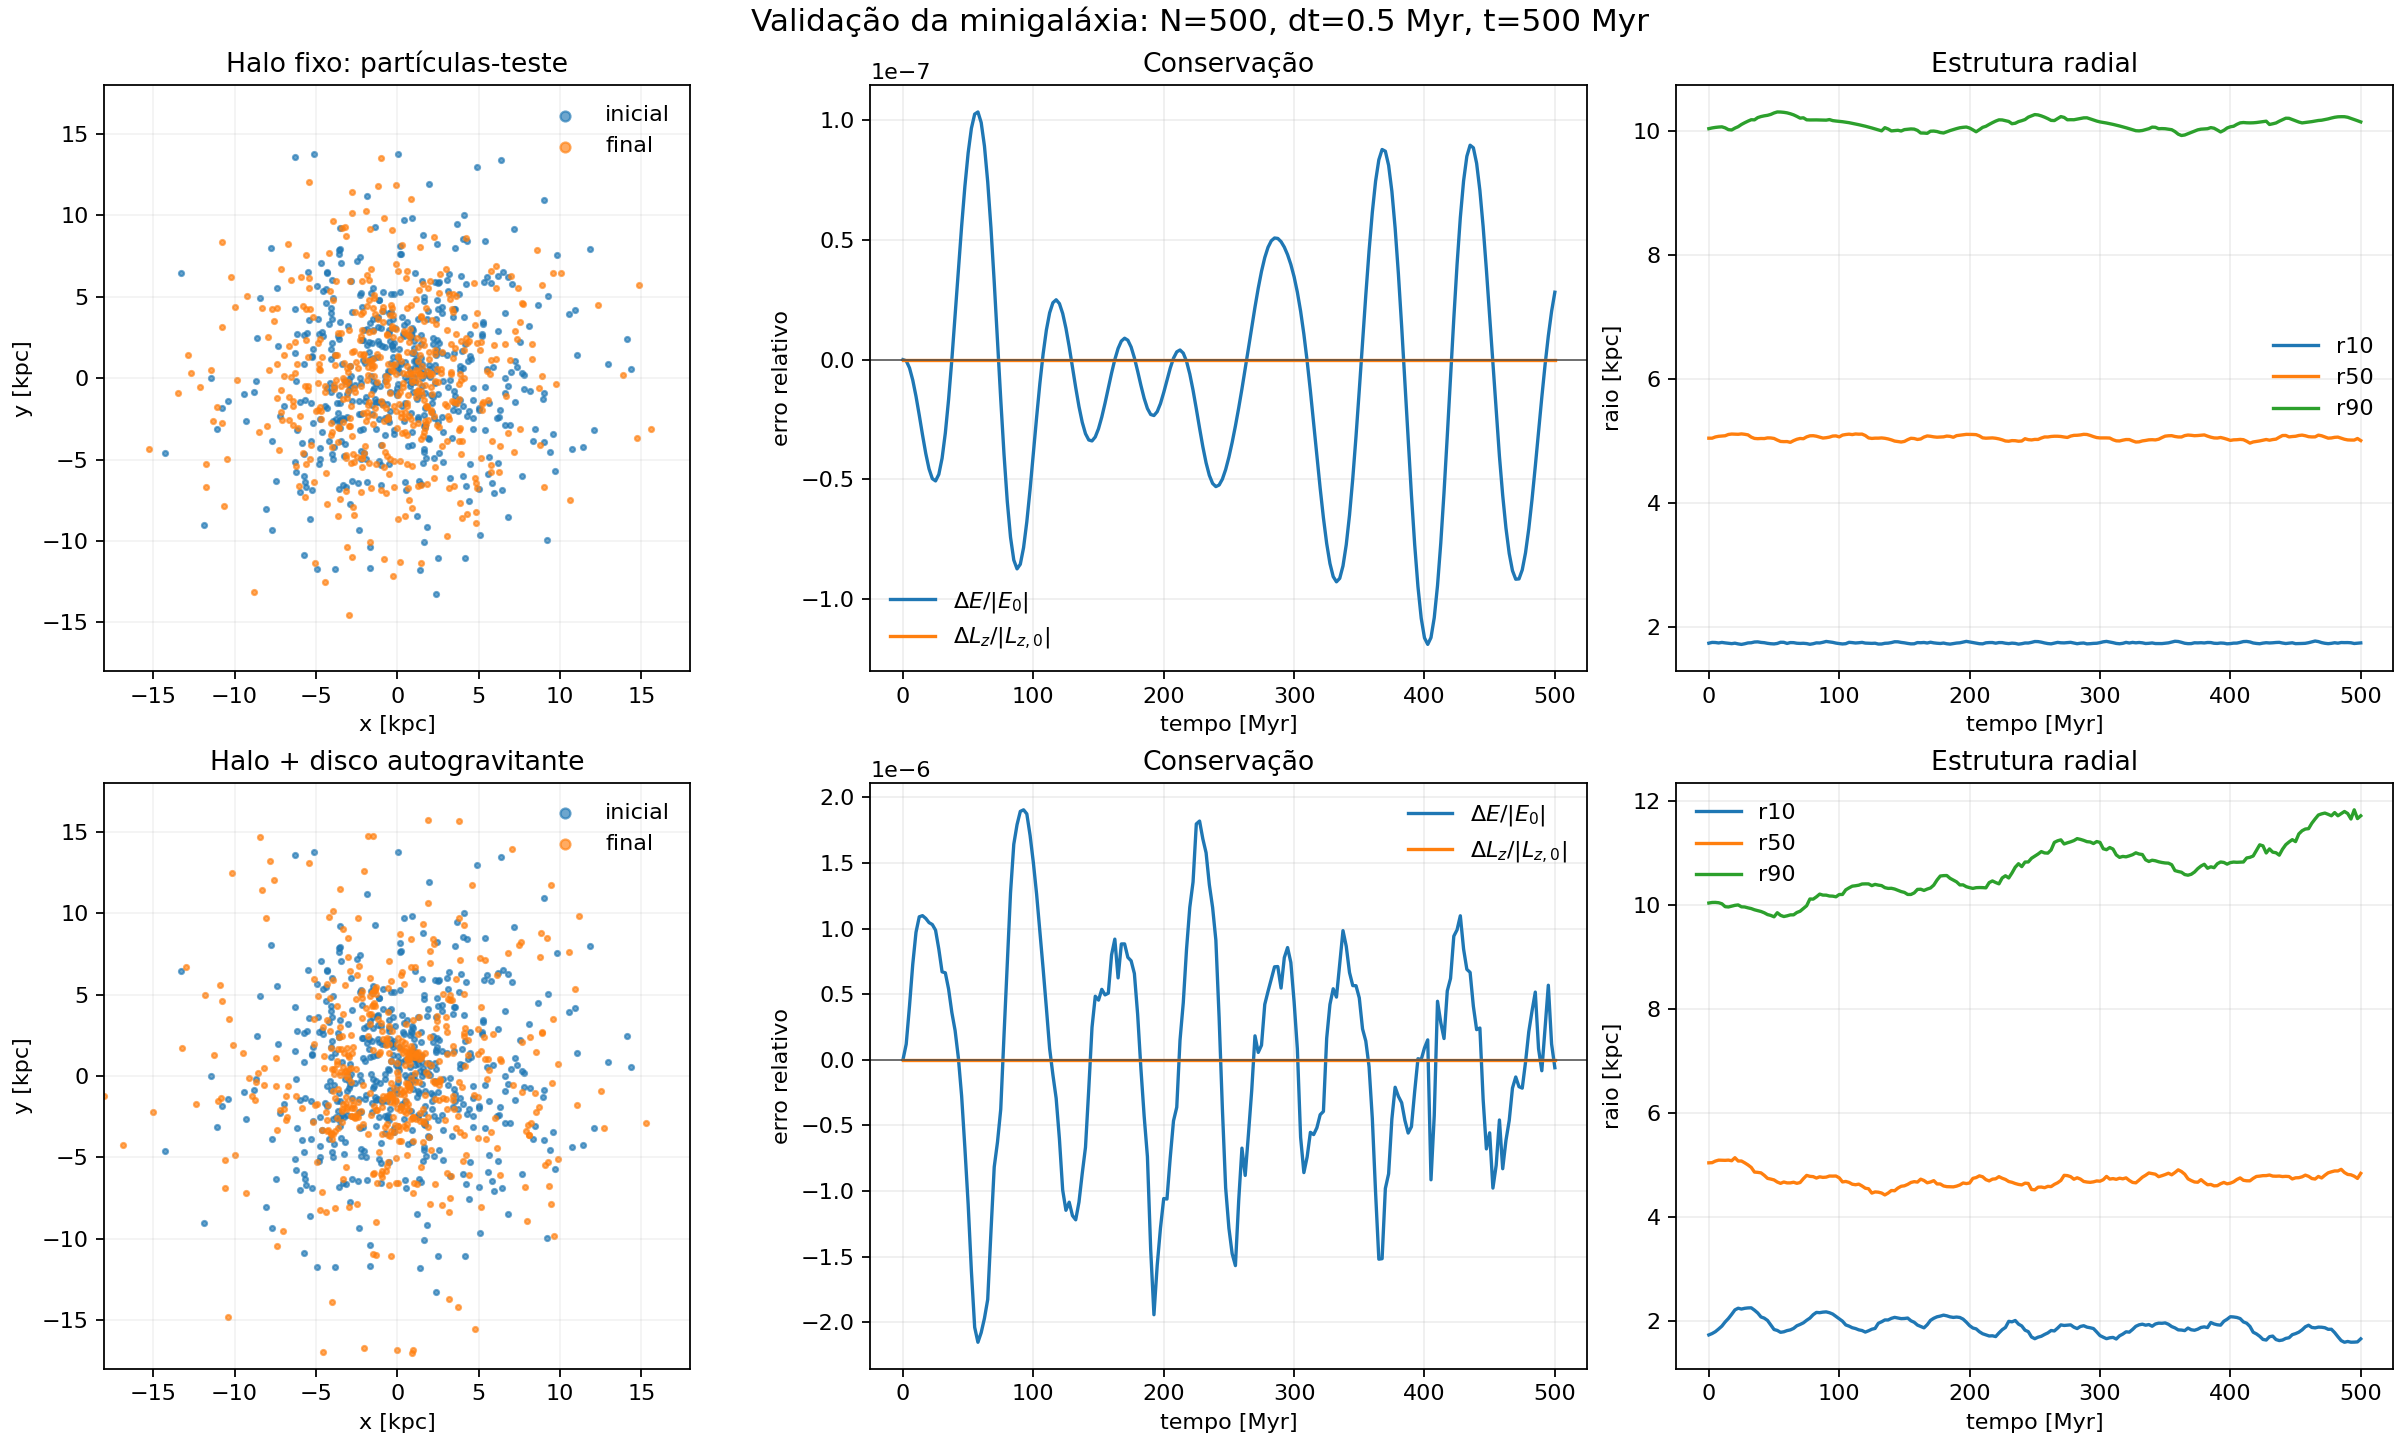

In [9]:
def plot_validation(p, halo_result, self_result):
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)

    cases = [
        ("Halo fixo: partículas-teste", halo_result),
        ("Halo + disco autogravitante", self_result),
    ]

    for row, (name, result) in enumerate(cases):
        ax = axes[row, 0]
        ax.scatter(*result["positions"][0].T, s=5, alpha=0.65, label="inicial")
        ax.scatter(*result["positions"][-1].T, s=5, alpha=0.65, label="final")
        ax.set(xlim=(-18, 18), ylim=(-18, 18), aspect="equal",
               xlabel="x [kpc]", ylabel="y [kpc]", title=name)
        ax.legend(frameon=False, markerscale=2)

        ax = axes[row, 1]
        energy = result["energy"]
        lz = result["lz"]
        ax.plot(result["time"], (energy - energy[0]) / abs(energy[0]),
                label=r"$\Delta E/|E_0|$")
        ax.plot(result["time"], (lz - lz[0]) / abs(lz[0]),
                label=r"$\Delta L_z/|L_{z,0}|$")
        ax.axhline(0.0, color="0.3", lw=0.7)
        ax.set(xlabel="tempo [Myr]", ylabel="erro relativo", title="Conservação")
        ax.legend(frameon=False)

        ax = axes[row, 2]
        for idx, label in enumerate(("r10", "r50", "r90")):
            ax.plot(result["time"], result["r_quantiles"][:, idx], label=label)
        ax.set(xlabel="tempo [Myr]", ylabel="raio [kpc]", title="Estrutura radial")
        ax.legend(frameon=False)

    fig.suptitle(
        f"Validação da minigaláxia: N={p.n}, dt={p.dt} Myr, t={p.t_end:.0f} Myr",
        fontsize=14,
    )
    return fig


fig = plot_validation(p, halo_result, self_result)
fig.savefig("validacao_minigalaxia.png", dpi=160)
plt.show()


## 7. Avaliação: conseguimos criar a minigaláxia?

**Sim — dentro do escopo didático definido.**

- No controle com halo fixo, os quantis radiais praticamente não mudaram em 500 Myr.
- No caso autogravitante, todas as partículas permaneceram dentro de 20 kpc.
- A energia apresentou deriva final da ordem de \(10^{-8}\), e \(L_z\) foi conservado até o limite de arredondamento.
- O disco autogravitante não permaneceu congelado: \(r_{50}\) caiu de 5,04 para 4,84 kpc e \(r_{90}\) aumentou de 10,04 para 11,71 kpc. Isso indica reorganização/aquecimento do disco, não explosão numérica.

Portanto, obtivemos um sistema **ligado, rotacionalmente sustentado e numericamente bem integrado**. Entretanto, ele ainda não é uma galáxia de pesquisa:

1. é um disco infinitamente fino em 2D;
2. o halo é analítico e não responde ao disco;
3. 500 superpartículas produzem relaxação de dois corpos artificialmente forte;
4. as velocidades iniciais usam uma aproximação, não uma função de distribuição de equilíbrio;
5. não há gás, formação estelar, feedback, enriquecimento químico ou cosmologia.

Essa distinção é importante: a animação é consequência de uma dinâmica coerente, mas não deve ser interpretada como uma previsão quantitativa para uma galáxia real.


## 8. Animação reprodutível no Colab

A rota principal usa o `PillowWriter`, disponível no Colab e independente de `ffmpeg`. O GIF também fica embutido na saída da célula.

Se você preferir um player interativo no próprio notebook, a função também pode ser convertida com `anim.to_jshtml()`. O GIF costuma ser menos temperamental e pode ser baixado diretamente.


In [10]:
def make_animation(result, title, max_frames=101, lim=18.0):
    times = result["time"]
    positions = result["positions"]
    frame_ids = np.linspace(
        0, len(times) - 1, min(max_frames, len(times)), dtype=int
    )

    fig, ax = plt.subplots(figsize=(6.2, 6.2), constrained_layout=True)
    ax.set(
        xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal",
        xlabel="x [kpc]", ylabel="y [kpc]", title=title,
    )
    ax.set_facecolor("#050814")
    scatter = ax.scatter([], [], s=7, c="#8bd3ff", alpha=0.8, edgecolors="none")
    clock = ax.text(0.03, 0.96, "", transform=ax.transAxes,
                    color="white", va="top")

    def update(frame_index):
        k = frame_ids[frame_index]
        scatter.set_offsets(positions[k])
        clock.set_text(f"t = {times[k]:.0f} Myr")
        return scatter, clock

    anim = FuncAnimation(
        fig, update, frames=len(frame_ids), interval=50,
        blit=True, repeat=True,
    )
    return fig, anim


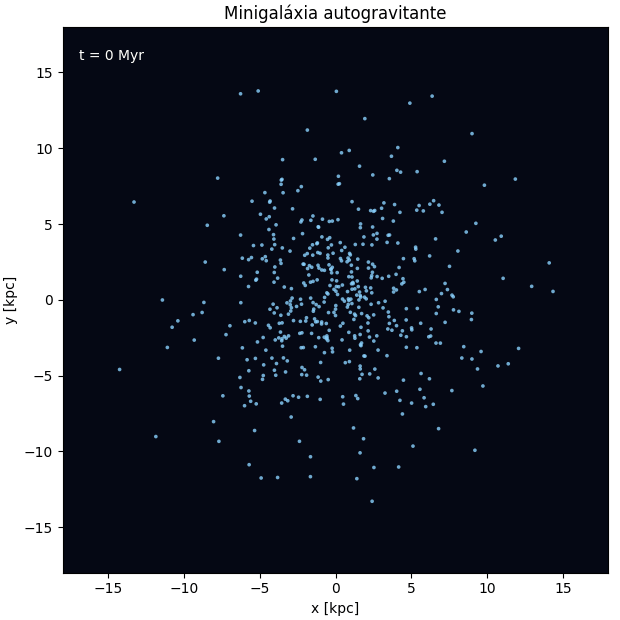

GIF salvo em: minigalaxia_autogravitante.gif


In [11]:
from IPython.display import Image, display

gif_path = "minigalaxia_autogravitante.gif"
fig_anim, anim = make_animation(
    self_result,
    "Minigaláxia autogravitante",
    max_frames=101,
)
anim.save(gif_path, writer=PillowWriter(fps=20), dpi=100)
plt.close(fig_anim)

display(Image(filename=gif_path))
print(f"GIF salvo em: {gif_path}")


In [ ]:
# Alternativa: player JavaScript embutido, sem criar arquivo.
GERAR_PLAYER_JSHTML = False

if GERAR_PLAYER_JSHTML:
    from IPython.display import HTML, display
    fig_js, anim_js = make_animation(
        self_result, "Minigaláxia autogravitante", max_frames=101
    )
    display(HTML(anim_js.to_jshtml(fps=20, default_mode="loop")))
    plt.close(fig_js)


In [ ]:
# No Colab, troque para True se quiser iniciar o download do GIF.
BAIXAR_GIF = False

if BAIXAR_GIF:
    try:
        from google.colab import files
        files.download(gif_path)
    except ImportError:
        print("Fora do Colab: o arquivo está em", gif_path)


In [12]:
# Salva os resultados numéricos para estudos posteriores.
np.savez_compressed(
    "resultados_minigalaxia.npz",
    parameters=np.array([
        p.n, p.m_halo, p.a_halo, p.m_disk, p.r_disk,
        p.r_max, p.epsilon, p.dt, p.t_end,
    ]),
    halo_time=halo_result["time"],
    halo_positions=halo_result["positions"],
    halo_energy=halo_result["energy"],
    halo_lz=halo_result["lz"],
    self_time=self_result["time"],
    self_positions=self_result["positions"],
    self_energy=self_result["energy"],
    self_lz=self_result["lz"],
)

print("Resultados salvos em resultados_minigalaxia.npz")


Resultados salvos em resultados_minigalaxia.npz


## 9. Próximos experimentos

Depois de entender esta versão-base, tente alterar **uma hipótese por vez**:

1. `epsilon`: compare 0,25, 0,50 e 1,00 kpc;
2. `dt`: verifique como a conservação de energia muda;
3. `m_halo`: observe a curva de rotação e a estabilidade do disco;
4. `m_disk`: torne a autogravidade mais ou menos importante;
5. `n`: compare 250, 500 e 1.000 partículas;
6. adicione uma massa perturbadora externa e procure caudas de maré;
7. substitua a aproximação das condições iniciais por um modelo de equilíbrio mais rigoroso.

O passo conceitual seguinte seria estudar **curvas de rotação e matéria escura**. Só depois faria sentido avançar para colisões de galáxias, Barnes–Hut, hidrodinâmica ou receitas de formação estelar.
